# 04 - Logistic Regression Baseline

Goal:
Train and evaluate the first supervised model for household financial fragility,
and establish the baselines every later model must beat.

This iteration uses 12 hand-selected predictors chosen for interpretability and relevance.

Primary outcome (`pay_casheqv`, defined in `03_preprocessing`):
- 1 = financially fragile (could not cover a $400 emergency with cash or equivalent)
- 0 = financially resilient on this measure

This notebook:
- reuses the exact train/test split saved by `03_preprocessing`
- reports a majority-class and a weighted-random baseline
- trains and evaluates with the survey weight `weight`, so results describe the
  U.S. adult population rather than the panel's composition
- reports ROC AUC, PR AUC, Brier score, and a weighted calibration curve
- re-fits the model without the near-target predictors `B2` and `EF1` to show how
  much of the performance depends on them

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

In [2]:
DATA_PATH = os.path.join(
    os.getcwd(),
    "..",
    "data",
    "raw",
    "SHED 2025 CSV Raw.csv"
)

df = pd.read_csv(DATA_PATH, low_memory=False)

print(df.shape)

(12934, 815)


## Target and Weights

Same definitions as `03_preprocessing`. `weight` is used for training and
evaluation; it is proportional to `weight_pop`, so either gives the same
percentages and model.

In [3]:
target = df["pay_casheqv"].map({
    "Yes": 0,
    "No": 1
})

sample_weight = df["weight"]

assert target.isna().sum() == 0

## Predictors

`B2` (overall financial well-being) and `EF1` (has a 3-month emergency fund) are
not the target, but they describe nearly the same condition. They are flagged as
near-target predictors and tested separately below.

In [4]:
categorical_features = [
    "B2",
    "EF1",
    "ppinc7",
    "FD3",
    "E2B",
    "A6",
    "ppeduc5",
    "GH1",
    "I9",
    "ppemploy"
]

numeric_features = [
    "ppage",
    "pphhsize"
]

near_target_features = [
    "B2",
    "EF1"
]

features = categorical_features + numeric_features

df[features].isna().sum()

B2          0
EF1         0
ppinc7      0
FD3         0
E2B         0
A6          0
ppeduc5     0
GH1         0
I9          0
ppemploy    0
ppage       0
pphhsize    0
dtype: int64

## Train/Test Split

Load the split saved by `03_preprocessing` so every model in the project is
evaluated on the same held-out respondents.

In [5]:
split = pd.read_csv(
    "../outputs/tables/train_test_split.csv"
).set_index("index")["split"]

assert split.index.equals(df.index)

train_idx = split.index[split == "train"]
test_idx = split.index[split == "test"]

X_train = df.loc[train_idx, features]
X_test = df.loc[test_idx, features]
y_train = target.loc[train_idx]
y_test = target.loc[test_idx]
w_train = sample_weight.loc[train_idx]
w_test = sample_weight.loc[test_idx]

print(X_train.shape, X_test.shape)

(10347, 12) (2587, 12)


In [6]:
def build_logistic_model(categorical, numeric):
    numeric_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ])

    categorical_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="NOT_ASKED"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ])

    preprocessor = ColumnTransformer([
        (
            "numeric",
            numeric_pipeline,
            numeric
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical
        )
    ])

    return Pipeline([
        ("preprocess", preprocessor),
        ("model", LogisticRegression(max_iter=2000))
    ])

In [7]:
def evaluate(name, y_true, prob, weights, threshold=0.5):
    pred = (prob >= threshold).astype(int)

    return {
        "Model": name,
        "ROC_AUC": roc_auc_score(y_true, prob, sample_weight=weights),
        "PR_AUC": average_precision_score(y_true, prob, sample_weight=weights),
        "Brier": brier_score_loss(y_true, prob, sample_weight=weights),
        "Accuracy": accuracy_score(y_true, pred, sample_weight=weights),
        "Precision": precision_score(y_true, pred, sample_weight=weights, zero_division=0),
        "Recall": recall_score(y_true, pred, sample_weight=weights),
        "F1": f1_score(y_true, pred, sample_weight=weights)
    }

## Baselines

- **Majority class:** always predicts "resilient" (probability 0 of fragility)
- **Weighted random:** guesses at random in proportion to the weighted share of
  fragile households in the training set

Every model must beat both.

In [8]:
majority_baseline = DummyClassifier(
    strategy="most_frequent"
).fit(X_train, y_train, sample_weight=w_train)

random_baseline = DummyClassifier(
    strategy="stratified",
    random_state=42
).fit(X_train, y_train, sample_weight=w_train)

prob_majority = majority_baseline.predict_proba(X_test)[:, 1]
prob_random = random_baseline.predict_proba(X_test)[:, 1]

## Logistic Regression

In [9]:
logistic_full = build_logistic_model(
    categorical_features,
    numeric_features
)

logistic_full.fit(
    X_train,
    y_train,
    model__sample_weight=w_train
)

prob_full = logistic_full.predict_proba(X_test)[:, 1]

In [10]:
reduced_categorical = [
    col for col in categorical_features
    if col not in near_target_features
]

logistic_reduced = build_logistic_model(
    reduced_categorical,
    numeric_features
)

logistic_reduced.fit(
    X_train[reduced_categorical + numeric_features],
    y_train,
    model__sample_weight=w_train
)

prob_reduced = logistic_reduced.predict_proba(
    X_test[reduced_categorical + numeric_features]
)[:, 1]

## Results

All metrics are survey-weighted on the held-out test set. Threshold-based
metrics (accuracy, precision, recall, F1) use a 0.5 cutoff.

In [11]:
results = pd.DataFrame([
    evaluate("Majority class baseline", y_test, prob_majority, w_test),
    evaluate("Weighted random baseline", y_test, prob_random, w_test),
    evaluate("Logistic Regression", y_test, prob_full, w_test),
    evaluate("Logistic Regression (no B2/EF1)", y_test, prob_reduced, w_test)
])

results.to_csv(
    "../outputs/tables/logistic_baseline_results.csv",
    index=False
)

results.round(3)

,Model,ROC_AUC,PR_AUC,Brier,Accuracy,Precision,Recall,F1
0,Majority class baseline,0.500,0.370,0.370,0.630,0.000,0.000,0.000
1,Weighted random baseline,0.498,0.370,0.469,0.531,0.368,0.372,0.370
2,Logistic Regression,0.899,0.836,0.120,0.839,0.802,0.752,0.776
3,Logistic Regression (no B2/EF1),0.867,0.792,0.140,0.798,0.761,0.662,0.708


In [12]:
baseline_rows = results["Model"].str.contains("baseline")
best_baseline = results[baseline_rows].agg({
    "ROC_AUC": "max",
    "PR_AUC": "max",
    "Brier": "min"
})

for model_name in ["Logistic Regression", "Logistic Regression (no B2/EF1)"]:
    row = results.set_index("Model").loc[model_name]
    beats = (
        row["ROC_AUC"] > best_baseline["ROC_AUC"]
        and row["PR_AUC"] > best_baseline["PR_AUC"]
        and row["Brier"] < best_baseline["Brier"]
    )
    print(f"{model_name} beats both baselines: {beats}")

Logistic Regression beats both baselines: True
Logistic Regression (no B2/EF1) beats both baselines: True


## Coefficients

Positive coefficients push toward "fragile"; negative toward "resilient".
Values are on the scaled / one-hot feature space.

In [13]:
def coefficient_table(model):
    names = model.named_steps["preprocess"].get_feature_names_out()
    coefs = model.named_steps["model"].coef_[0]

    return pd.DataFrame({
        "feature": names,
        "coefficient": coefs
    }).sort_values("coefficient", ascending=False)


coefficients_full = coefficient_table(logistic_full)
coefficients_reduced = coefficient_table(logistic_reduced)

coefficients_full.to_csv(
    "../outputs/tables/logistic_coefficients.csv",
    index=False
)

coefficients_reduced.to_csv(
    "../outputs/tables/logistic_coefficients_no_near_target.csv",
    index=False
)

coefficients_full

,feature,coefficient
3,categorical__B2_Finding it difficult to get by,0.969523
6,categorical__EF1_No,0.895008
14,"categorical__ppinc7_Less than $10,000",0.747932
18,categorical__FD3_Sometimes not enough to eat,0.488796
17,categorical__FD3_Often not enough to eat,0.428266
20,categorical__E2B_Yes,0.399400
22,categorical__A6_Not confident,0.387295
8,"categorical__ppinc7_$10,000 to $24,999",0.386967
4,categorical__B2_Just getting by,0.365893
28,categorical__ppeduc5_No high school diploma or...,0.315976


## Calibration Curve

`sklearn.calibration.calibration_curve` does not accept survey weights, so the
curve is computed directly: predictions are grouped into 10 equal-width bins, and
each bin's weighted mean prediction is plotted against its weighted observed
fragility rate. Points on the diagonal mean the predicted probabilities can be
read as real probabilities.

In [14]:
def weighted_calibration(y_true, prob, weights, n_bins=10):
    y_true = np.asarray(y_true)
    prob = np.asarray(prob)
    weights = np.asarray(weights)

    edges = np.linspace(0, 1, n_bins + 1)
    bin_ids = np.clip(np.digitize(prob, edges) - 1, 0, n_bins - 1)

    rows = []
    for b in range(n_bins):
        in_bin = bin_ids == b
        if not in_bin.any():
            continue
        rows.append({
            "mean_predicted": np.average(prob[in_bin], weights=weights[in_bin]),
            "observed_rate": np.average(y_true[in_bin], weights=weights[in_bin]),
            "n": int(in_bin.sum())
        })

    return pd.DataFrame(rows)


calibration_full = weighted_calibration(y_test, prob_full, w_test)
calibration_reduced = weighted_calibration(y_test, prob_reduced, w_test)

calibration_full.round(3)

,mean_predicted,observed_rate,n
0,0.049,0.056,1043
1,0.146,0.182,285
2,0.248,0.221,174
3,0.347,0.319,117
4,0.452,0.412,126
5,0.549,0.595,121
6,0.652,0.660,99
7,0.753,0.802,148
8,0.855,0.829,186
9,0.946,0.925,288


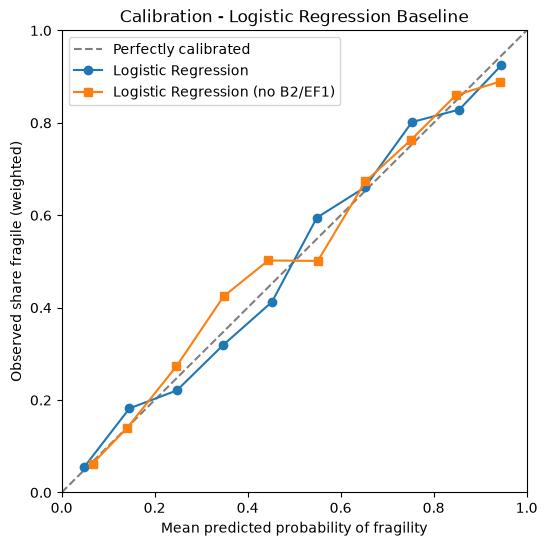

In [15]:
os.makedirs("../outputs/figures", exist_ok=True)

fig, ax = plt.subplots(figsize=(6, 6))

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfectly calibrated")
ax.plot(
    calibration_full["mean_predicted"],
    calibration_full["observed_rate"],
    marker="o",
    label="Logistic Regression"
)
ax.plot(
    calibration_reduced["mean_predicted"],
    calibration_reduced["observed_rate"],
    marker="s",
    label="Logistic Regression (no B2/EF1)"
)

ax.set_xlabel("Mean predicted probability of fragility")
ax.set_ylabel("Observed share fragile (weighted)")
ax.set_title("Calibration - Logistic Regression Baseline")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend()

fig.savefig(
    "../outputs/figures/calibration_logistic_baseline.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

## Baseline Summary

Survey-weighted, held-out test set (2,587 respondents):

| Model | ROC AUC | PR AUC | Brier |
|---|---|---|---|
| Majority class baseline | 0.500 | 0.370 | 0.370 |
| Weighted random baseline | 0.498 | 0.370 | 0.469 |
| Logistic Regression (12 features) | 0.899 | 0.836 | 0.120 |
| Logistic Regression (no B2/EF1) | 0.867 | 0.792 | 0.140 |

- Both logistic models beat both baselines on every metric.
- The full model reproduces the ROC AUC, PR AUC, and Brier score of the
  first iteration exactly.
- The calibration curve tracks the diagonal closely; predicted probabilities can
  be read as approximate real-world rates.
- Removing the near-target predictors `B2` and `EF1` costs about 0.03 ROC AUC
  and 0.04 PR AUC. The model still performs well without them, so most of its
  signal comes from income, food security, confidence, education, and housing.
- **Open question for the Challenge Advisor:** should `B2` and `EF1` stay in the
  feature set, given that they describe nearly the same condition as the target?

This is the baseline the October tree-based and gradient-boosted models must beat.